# MediaPipe keypoints → sign classifier

Converts the MediaPipe keypoints saved by the pose-degradation notebook (`cache/prep_*/keypoints/...`) into the format `sign_classifier.ipynb` expects: **one `.npz` per video**, one keypoint folder per scenario (original, `resolution_96`, `fps_5`, ...).

**How to use**
1. Run the pose-degradation notebook first, so the keypoints are in its cache.
2. Set the paths in section 2.
3. Run all cells. Then point `KP_DIR` in the classifier notebook at one of the folders in `keypoints/`.

```
cache/prep_xxxxxx/keypoints/<setting>/<scenario>/rep0/<sign>__<video>.npz    (input, from the degradation notebook)
keypoints/kp_mediapipe_<scenario>/<sign>/<video>.npz                          (output, for the classifier)
```

## 1. What the conversion does

| Classifier needs | From MediaPipe |
| --- | --- |
| `kp2d` `[T, 52, 2]` in **pixels** | cached `xy` (0-1) times the frame width and height. Pixels keep the aspect ratio, which the shoulder-width scaling in the classifier relies on |
| `conf` `[T, 52]` | pose visibility for body joints, hand score for finger joints. Missing keypoints get 0, so the classifier treats them as missing |
| `joint_names` | same 52 names and order as the SMPLest-X runs: `Neck`, shoulders, elbows, wrists, ears, eyes, `Nose`, then 20 points per hand (`L_Thumb_1` ... `R_Pinky_4`) |

* **Neck**: MediaPipe has no neck point, so it is the midpoint of the shoulders (confidence = the lower of the two).
* **Hands**: MediaPipe gives 21 points per hand. The wrist is dropped because it is already the body wrist, leaving 20 finger points, as in the SMPLest-X joint set.
* **Left / right** is the signer's own left and right, so `L_`/`R_` mirroring in the classifier works.
* **File names**: the degradation notebook names videos `<sign>__<video>`. The prefix is removed, so the file name matches the `Video file` column of `all_videos.txt`, and the sign becomes the folder name (needed for `LABEL = "folder"`).
* **No `kp3d`**: the degradation notebook only saved 2D keypoints, so use `COORDS = "2d"` in the classifier.

## 2. Settings

In [1]:
# Where the pose-degradation notebook saved its keypoints
CACHE_FOLDER = "cache"      # CACHE_FOLDER of the degradation notebook
PREP         = None         # which "prep_xxxxxx" folder inside the cache; None = the newest
SETTING      = None         # MediaPipe setting folder; None = the only one (set it if there are several)
REPETITION   = 0            # which repetition to use (rep0, rep1, ...)
SCENARIOS    = None         # None = every scenario, or a list such as ["original", "resolution_96", "fps_5"]

# Where the classifier looks for keypoints
OUT_ROOT     = "keypoints"  # one folder per scenario: keypoints/kp_mediapipe_<scenario>/<sign>/<video>.npz
PREFIX       = "kp_mediapipe_"
DATA         = "dataset"    # same as the classifier notebook: all_videos.txt is found anywhere inside
MIN_CONF     = 0.3          # same as the classifier notebook

STRIP_SIGN_PREFIX = True    # "hello__13200919064508332-HELLO" -> sign "hello", video "13200919064508332-HELLO"

## 3. Converter

Joint mapping and the conversion of one file.

In [2]:
import csv, os, re, shlex, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd

# Slots in the cached MediaPipe keypoints (553 per frame): pose 0-32, left hand 33-53, right hand 54-74, face 75-552.
# A hand is its wrist followed by 4 points per finger (thumb, index, middle, ring, pinky). The classifier's joint
# set has the wrist once (from the pose), so each hand contributes its 20 finger points.
BODY = ["Neck", "L_Shoulder", "R_Shoulder", "L_Elbow", "R_Elbow", "L_Wrist", "R_Wrist",
        "L_Ear", "R_Ear", "L_Eye", "R_Eye", "Nose"]
POSE_SLOT = {"L_Shoulder": 11, "R_Shoulder": 12, "L_Elbow": 13, "R_Elbow": 14, "L_Wrist": 15, "R_Wrist": 16,
             "L_Ear": 7, "R_Ear": 8, "L_Eye": 2, "R_Eye": 5, "Nose": 0}
FINGERS = ["Thumb", "Index", "Middle", "Ring", "Pinky"]
HAND = {s: [f"{s}_{f}_{i}" for f in FINGERS for i in range(1, 5)] for s in "LR"}
HAND_START = {"L": 33, "R": 54}

JOINT_NAMES = BODY + HAND["L"] + HAND["R"]            # 52 joints, same names and order as the SMPLest-X runs
SLOT = dict(POSE_SLOT)
for s in "LR":
    for k, name in enumerate(HAND[s]):
        SLOT[name] = HAND_START[s] + 1 + k            # +1 skips the hand's wrist
LEFT_HAND, RIGHT_HAND = slice(len(BODY), len(BODY) + 20), slice(len(BODY) + 20, len(BODY) + 40)


def convert(d):
    """One cached MediaPipe file (xy and conf, normalised 0-1) -> the classifier's format."""
    xy, conf = d["xy"].astype(np.float32), d["conf"].astype(np.float32)
    w, h = (float(v) for v in d["size"])
    kp = np.full((len(xy), len(JOINT_NAMES), 2), np.nan, np.float32)
    cf = np.zeros((len(xy), len(JOINT_NAMES)), np.float32)
    for j, name in enumerate(JOINT_NAMES):
        if name == "Neck":                            # MediaPipe has no neck: midpoint of the shoulders
            kp[:, j] = (xy[:, 11] + xy[:, 12]) / 2
            cf[:, j] = np.minimum(conf[:, 11], conf[:, 12])
        else:
            kp[:, j] = xy[:, SLOT[name]]
            cf[:, j] = conf[:, SLOT[name]]
    kp *= np.array([w, h], np.float32)                # normalised -> pixels
    cf[~np.isfinite(kp).all(-1)] = 0                  # not found = confidence 0
    return {"kp2d": kp, "conf": cf, "joint_names": np.array(JOINT_NAMES),
            "image_hw": np.array([int(h), int(w)]), "video_fps": np.float32(d["fps"])}


def quality(out):
    """What the classifier will see: it drops joints below MIN_CONF, then needs both shoulders in at least one frame."""
    ok = np.isfinite(out["kp2d"]).all(-1) & (out["conf"] >= MIN_CONF)
    shoulders = ok[:, JOINT_NAMES.index("L_Shoulder")] & ok[:, JOINT_NAMES.index("R_Shoulder")]
    hands = ok[:, LEFT_HAND].any(1) | ok[:, RIGHT_HAND].any(1)
    return {"usable": bool(shoulders.any()), "shoulders_found": float(shoulders.mean()),
            "hand_found": float(hands.mean())}


def split_name(stem):
    """'<sign>__<video>' -> (sign, video)."""
    if STRIP_SIGN_PREFIX and "__" in stem:
        sign, video = stem.split("__", 1)
        return sign, video
    return "unknown", stem

## 4. Find the MediaPipe keypoints

`sources` maps every scenario to the folder with its keypoint files. Edit it by hand if your keypoints are somewhere else, as long as the files have `xy`, `conf`, `size` and `fps` (the degradation notebook's format).

In [3]:
def find_sources():
    preps = [p for p in Path(CACHE_FOLDER).glob("prep_*") if (p / "keypoints").is_dir()]
    if not preps:
        raise FileNotFoundError(f"No prep_*/keypoints folder in {Path(CACHE_FOLDER).resolve()}. "
                                "Run the pose-degradation notebook first, or fix CACHE_FOLDER.")
    prep = Path(CACHE_FOLDER) / PREP if PREP else max(preps, key=lambda p: p.stat().st_mtime)
    if len(preps) > 1 and not PREP:
        print("several prep folders found, using the newest:", prep.name, "| others:",
              [p.name for p in preps if p != prep])
    settings = sorted(p.name for p in (prep / "keypoints").iterdir() if p.is_dir())
    setting = SETTING or (settings[0] if len(settings) == 1 else None)
    if setting is None:
        raise ValueError(f"Several MediaPipe settings found, set SETTING to one of: {settings}")

    root = prep / "keypoints" / setting
    folders = {d.name: d / f"rep{REPETITION}" for d in sorted(root.iterdir()) if (d / f"rep{REPETITION}").is_dir()}
    # degraded scenario folders end in a 6-character hash ("fps_5_a1b2c3"); drop it for readable names
    names = {k: re.sub(r"_[0-9a-f]{6}$", "", k) for k in folders}
    if len(set(names.values())) < len(names):
        names = {k: k for k in folders}
    sources = {names[k]: v for k, v in folders.items()}
    if SCENARIOS:
        missing = [s for s in SCENARIOS if s not in sources]
        if missing:
            print("not found, skipped:", missing, "| available:", list(sources))
        sources = {s: sources[s] for s in SCENARIOS if s in sources}
    sources = dict(sorted(sources.items(), key=lambda kv: (kv[0] != "original", kv[0])))
    print(f"{prep.name} / {setting} / rep{REPETITION}: {len(sources)} scenarios")
    return sources


sources = find_sources()
pd.DataFrame({"scenario": list(sources), "files": [len(list(p.glob('*.npz'))) for p in sources.values()]})

prep_81acb4 / model_complexity=1,min_detection_confidence=0.5 / rep0: 23 scenarios


,scenario,files
0,original,20
1,codec_libvpx-vp9,20
2,codec_libx264,20
3,codec_libx265,20
4,codec_mjpeg,20
5,codec_mpeg4,20
6,compression_23,20
7,compression_28,20
8,compression_33,20
9,compression_38,20


## 5. Convert

One folder per scenario in `keypoints/`. The table shows what the classifier will be able to use: **unusable** videos have no frame with both shoulders found, so the classifier skips them. Heavily degraded scenarios will lose videos here.

In [4]:
def convert_all(sources):
    rows = []
    for n, (scenario, folder) in enumerate(sources.items(), 1):
        out_dir = Path(OUT_ROOT) / f"{PREFIX}{scenario}"
        stats = []
        files = sorted(folder.glob("*.npz"))
        for f in files:
            with np.load(f) as d:
                out = convert(d)
            sign, video = split_name(f.stem)
            target = out_dir / sign / f"{video}.npz"
            target.parent.mkdir(parents=True, exist_ok=True)
            np.savez_compressed(target, **out)
            stats.append(quality(out))
        q = pd.DataFrame(stats)
        rows.append({"scenario": scenario, "kp_dir": str(out_dir), "videos": len(files),
                     "unusable": int((~q.usable).sum()) if len(q) else 0,
                     "shoulders_found": round(q.shoulders_found.mean(), 3) if len(q) else np.nan,
                     "hand_found": round(q.hand_found.mean(), 3) if len(q) else np.nan})
        print(f"\r[{n}/{len(sources)}] {scenario}: {len(files)} videos        ", end="")
    print()
    summary = pd.DataFrame(rows)
    summary.to_csv(Path(OUT_ROOT) / "mediapipe_conversion_summary.csv", index=False)
    return summary


conversion = convert_all(sources)
conversion

[23/23] resolution_96: 20 videos          


,scenario,kp_dir,videos,unusable,shoulders_found,hand_found
0,original,keypoints/kp_mediapipe_original,20,0,1.0,0.489
1,codec_libvpx-vp9,keypoints/kp_mediapipe_codec_libvpx-vp9,20,0,1.0,0.491
2,codec_libx264,keypoints/kp_mediapipe_codec_libx264,20,0,1.0,0.490
3,codec_libx265,keypoints/kp_mediapipe_codec_libx265,20,0,1.0,0.486
4,codec_mjpeg,keypoints/kp_mediapipe_codec_mjpeg,20,0,1.0,0.477
5,codec_mpeg4,keypoints/kp_mediapipe_codec_mpeg4,20,0,1.0,0.475
6,compression_23,keypoints/kp_mediapipe_compression_23,20,0,1.0,0.491
7,compression_28,keypoints/kp_mediapipe_compression_28,20,0,1.0,0.491
8,compression_33,keypoints/kp_mediapipe_compression_33,20,0,1.0,0.504
9,compression_38,keypoints/kp_mediapipe_compression_38,20,0,1.0,0.505


## 6. Checks

**Look at one video.** Left joints are blue, right joints green, neck and nose orange. In a normal (not mirrored) video the signer's left side is on the *right* of the image. If hands or sides look swapped, stop here and tell me before training.

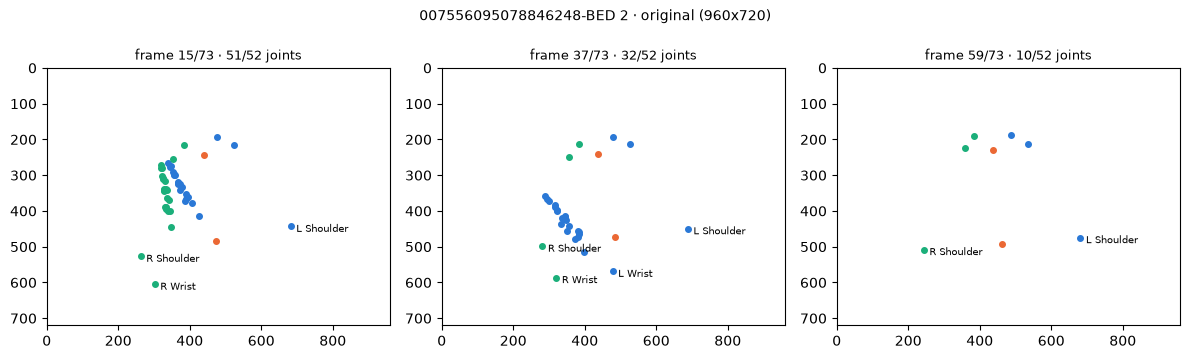

In [5]:
import matplotlib.pyplot as plt


def look(scenario="original", video=0, moments=(0.2, 0.5, 0.8)):
    files = sorted((Path(OUT_ROOT) / f"{PREFIX}{scenario}").rglob("*.npz"))
    with np.load(files[video]) as d:
        kp, cf, names, (h, w) = d["kp2d"], d["conf"], [str(n) for n in d["joint_names"]], d["image_hw"]
    side = np.array([0 if n.startswith("L_") else 1 if n.startswith("R_") else 2 for n in names])
    colors = ["#2a78d6", "#1baf7a", "#eb6834"]
    fig, axes = plt.subplots(1, len(moments), figsize=(4 * len(moments), 3.6), squeeze=False)
    for ax, m in zip(axes[0], moments):
        t = min(int(m * len(kp)), len(kp) - 1)
        ok = np.isfinite(kp[t]).all(-1) & (cf[t] >= MIN_CONF)
        for s, c in enumerate(colors):
            pick = (side == s) & ok
            ax.scatter(kp[t, pick, 0], kp[t, pick, 1], s=16, color=c)
        for name in ("L_Shoulder", "R_Shoulder", "L_Wrist", "R_Wrist"):
            j = names.index(name)
            if ok[j]:
                ax.annotate(name.replace("_", " "), kp[t, j], fontsize=7, xytext=(4, -4), textcoords="offset points")
        ax.set_xlim(0, w); ax.set_ylim(h, 0); ax.set_aspect("equal")
        ax.set_title(f"frame {t + 1}/{len(kp)} · {ok.sum()}/{len(names)} joints", fontsize=9)
    fig.suptitle(f"{files[video].stem} · {scenario} ({w}x{h})", fontsize=10)
    fig.tight_layout()
    plt.show()


look("original")

**Match against `all_videos.txt`.** The classifier takes labels and the train/val/test split from this list and only uses videos whose file name is in it.

In [6]:
def check_against_list(scenario="original"):
    hits = sorted(os.path.join(r, f) for r, _, fs in os.walk(DATA) for f in fs
                  if f == "all_videos.txt" and "__MACOSX" not in r)
    if not hits:
        print(f"all_videos.txt not found under {DATA!r}. The classifier needs it for labels and splits.")
        return None
    with open(hits[0], newline="", encoding="utf-8") as f:
        rows = [{k.strip(): (v or "").strip() for k, v in r.items()} for r in csv.DictReader(f)]
    listed = {Path(r["Video file"]).stem.lower(): r for r in rows}
    mine = {p.stem.lower(): p.parent.name for p in (Path(OUT_ROOT) / f"{PREFIX}{scenario}").rglob("*.npz")}

    matched = [s for s in mine if s in listed]
    print(f"list: {hits[0]}")
    print(f"{len(mine)} converted videos: {len(matched)} found in the list, {len(mine) - len(matched)} not")
    if len(matched) < len(mine):
        print("  not in the list (the classifier ignores them), for example:", sorted(set(mine) - set(matched))[:5])
    print(f"{len(rows) - len(matched)} of {len(rows)} rows in the list have no keypoints "
          "(expected if you only converted a subset of the dataset)")
    if not matched:
        print("No video matches: check that the video file names in the list equal the converted file names.")
        return None

    df = pd.DataFrame([{**listed[s], "folder": mine[s]} for s in matched])
    df["split"] = df["Split"].str.lower()
    for s in ("train", "val", "test"):
        if s not in set(df.split):
            print(f"WARNING: no {s} videos - the classifier needs all three splits")
    unseen = set(df[df.split != "train"].Gloss) - set(df[df.split == "train"].Gloss)
    if unseen:
        print(f"WARNING: {len(unseen)} signs appear in val/test but not in train (they cannot be learned):",
              sorted(unseen)[:8])
    differs = int((df.Gloss.str.lower() != df.folder.str.lower()).sum())
    print(f"{differs} videos where the folder name differs from the Gloss "
          "(LABEL = 'gloss' uses the Gloss, 'folder' keeps such variants apart)")
    return df.groupby("split").agg(videos=("Video file", "count"), signs=("Gloss", "nunique"),
                                   participants=("Participant ID", "nunique"))


check_against_list()

all_videos.txt not found under 'dataset'. The classifier needs it for labels and splits.


## 7. Run the classifier

Open `sign_classifier.ipynb` and set, for each scenario you want:

```python
KP_DIR   = "keypoints/kp_mediapipe_original"     # or kp_mediapipe_resolution_96, ...
COORDS   = "2d"
RUN_NAME = "mediapipe_2d_original"               # a new name per scenario
```

The cell below prints the matching terminal command for every scenario (same arguments as section 6 of the classifier notebook). Set `RUN_NOW = True` to run them all one after another. That trains a model per scenario (3 seeds x 200 epochs each), so it is slow without a GPU. Afterwards, section 8 of the classifier notebook lists all runs side by side.

**Note:** the classifier script trains and tests inside one `KP_DIR`. Each scenario is therefore a separate classifier trained and tested on that scenario's keypoints. It does not train on clean keypoints and test on degraded ones.

In [7]:
SEEDS, LABEL, MIRROR = 3, "gloss", False      # as in section 2 of the classifier notebook
RUN_NOW = False                                # True = train one model per scenario (slow)

commands = []
for scenario in sources:
    commands.append(["python", "sign_classifier.py", "--data_root", DATA,
                     "--kp_dir", str(Path(OUT_ROOT) / f"{PREFIX}{scenario}"), "--coords", "2d",
                     "--seeds", str(SEEDS), "--min_conf", str(MIN_CONF), "--label", LABEL,
                     *(["--mirror"] if MIRROR else []), "--out_dir", f"results/mediapipe_2d_{scenario}"])
for c in commands:
    print(shlex.join(c))
if RUN_NOW:
    for c in commands:
        subprocess.run([sys.executable if c[0] == "python" else c[0], *c[1:]], check=True)

python sign_classifier.py --data_root dataset --kp_dir keypoints/kp_mediapipe_original --coords 2d --seeds 3 --min_conf 0.3 --label gloss --out_dir results/mediapipe_2d_original
python sign_classifier.py --data_root dataset --kp_dir keypoints/kp_mediapipe_codec_libvpx-vp9 --coords 2d --seeds 3 --min_conf 0.3 --label gloss --out_dir results/mediapipe_2d_codec_libvpx-vp9
python sign_classifier.py --data_root dataset --kp_dir keypoints/kp_mediapipe_codec_libx264 --coords 2d --seeds 3 --min_conf 0.3 --label gloss --out_dir results/mediapipe_2d_codec_libx264
python sign_classifier.py --data_root dataset --kp_dir keypoints/kp_mediapipe_codec_libx265 --coords 2d --seeds 3 --min_conf 0.3 --label gloss --out_dir results/mediapipe_2d_codec_libx265
python sign_classifier.py --data_root dataset --kp_dir keypoints/kp_mediapipe_codec_mjpeg --coords 2d --seeds 3 --min_conf 0.3 --label gloss --out_dir results/mediapipe_2d_codec_mjpeg
python sign_classifier.py --data_root dataset --kp_dir keypoints/kp_